In [72]:
import tensorflow as tf
import numpy as np
import tensorflow_datasets as tfds
import tensorflow_text
import matplotlib.pyplot as plt

# Data Preprocessing and Tokenizing

In [2]:
X_pten, metadata_pten = tfds.load('ted_hrlr_translate/pt_to_en', with_info = True, as_supervised = True)
X_ruen, metadata_ruen = tfds.load('ted_hrlr_translate/ru_to_en', with_info = True, as_supervised = True)
X_Train_pten, X_Validate_pten = X_pten["train"], X_pten["validation"]
X_Train_ruen, X_Validate_ruen = X_ruen["train"], X_ruen["validation"]

In [2]:
tokenizers_pten = tf.saved_model.load("Preprocess/pt_en_converter")
tokenizers_ruen = tf.saved_model.load("Preprocess/ru_en_converter")

In [4]:
MAX_TOKENS = 128
def prepare_batch_pten(inp, out):
    inp = tokenizers_pten.pt.tokenize(inp)
    inp = inp[:, :MAX_TOKENS]
    inp = inp.to_tensor()
    out = tokenizers_pten.en.tokenize(out)
    out = out[:, :(MAX_TOKENS + 1)]
    out_inputs = out[:, :-1].to_tensor()
    out_labels = out[:, 1:].to_tensor()
    return (inp, out_inputs), out_labels
def prepare_batch_ruen(out, inp):
    inp = tokenizers_ruen.en.tokenize(inp)
    inp = inp[:, :MAX_TOKENS]
    inp = inp.to_tensor()
    out = tokenizers_ruen.ru.tokenize(out)
    out = out[:, :(MAX_TOKENS + 1)]
    out_inputs = out[:, :-1].to_tensor()
    out_labels = out[:, 1:].to_tensor()
    return (inp, out_inputs), out_labels

In [5]:
BUFFER_SIZE = 20000
BATCH_SIZE = 32
def make_batches_pten(ds):
    return (ds.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).map(prepare_batch_pten, tf.data.AUTOTUNE).prefetch(buffer_size=tf.data.AUTOTUNE))
def make_batches_ruen(ds):
    return (ds.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).map(prepare_batch_ruen, tf.data.AUTOTUNE).prefetch(buffer_size=tf.data.AUTOTUNE))

In [6]:
train_batches_pten = make_batches_pten(X_Train_pten)
val_batches_pten = make_batches_pten(X_Validate_pten)
train_batches_enru = make_batches_ruen(X_Train_ruen)
val_batches_enru = make_batches_ruen(X_Validate_ruen)

# Transformer Model

In [30]:
def positional_encoding(length, depth):
    depth = depth / 2
    positions = np.arange(length)[:, np.newaxis]
    depths = np.arange(depth)[np.newaxis:, ] / depth
    angle_rads = (positions / (10000 ** depths))
    pos_enc = np.concatenate([np.sin(angle_rads), np.cos(angle_rads)], axis = -1)
    return tf.cast(pos_enc, dtype = tf.float32)

In [31]:
class PositionalEmbedding(tf.keras.layers.Layer):
    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.d_model = d_model
        self.embedding = tf.keras.layers.Embedding(vocab_size, d_model)
        self.pos_enc = positional_encoding(2048, d_model)
        
    def compute_mask(self, *args, **kwargs):
        return self.embedding.compute_mask(*args, **kwargs)
    
    def call(self, X):
        length = tf.shape(X)[1]
        X = self.embedding(X)
        X *= tf.math.sqrt(tf.cast(self.d_model, dtype = tf.float32))
        return X + self.pos_enc[tf.newaxis, :length, :]

In [32]:
class BaseAttention(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__()
        self.mha = tf.keras.layers.MultiHeadAttention(**kwargs)
        self.layer_norm = tf.keras.layers.LayerNormalization()
        self.add = tf.keras.layers.Add()

In [33]:
class GlobalSelfAttention(BaseAttention):
    def call(self, X):
        self_attention = self.mha(query = X, value = X, key = X)
        out = self.add([X, self_attention])
        return self.layer_norm(out)

In [34]:
class CrossAttention(BaseAttention):
    def call(self, X, Context):
        cross_attention, attn_scores = self.mha(query = X, key = Context, value = Context, return_attention_scores = True)
        self.last_attn_scores = attn_scores
        out = self.add([X, cross_attention])
        return self.layer_norm(out)

In [35]:
class CasualSelfAttention(BaseAttention):
    def call(self, X):
        masked_attention = self.mha(query = X, key = X, value = X, use_causal_mask = True)
        out = self.add([X, masked_attention])
        return self.layer_norm(out)

In [36]:
class FeedForward(tf.keras.layers.Layer):
    def __init__(self, units, d_model, dropout_rate = 0.1):
        super().__init__()
        self.d_model = d_model
        self.seq = tf.keras.Sequential([
            tf.keras.layers.Dense(units, activation = 'relu'),
            tf.keras.layers.Dense(d_model),
            tf.keras.layers.Dropout(dropout_rate)
        ])
        self.layer_norm = tf.keras.layers.LayerNormalization()
        self.add = tf.keras.layers.Add()
    def call(self, X):
        X_ = self.seq(X)
        out = self.add([X, X_])
        return self.layer_norm(out)

In [37]:
class EncoderLayer(tf.keras.layers.Layer):
    def __init__(self, heads, units, d_model, dropout_rate):
        super().__init__()
        self.gsa = GlobalSelfAttention(num_heads = heads, key_dim = d_model, dropout = dropout_rate)
        self.feed_forward = FeedForward(units, d_model, dropout_rate = 0.1)
    def call(self, X):
        out = self.gsa(X)
        return self.feed_forward(out)

In [38]:
class Encoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, vocab_size, heads, units, d_model, dropout_rate):
        super().__init__()
        self.num_layers = num_layers
        self.pos_emb = PositionalEmbedding(vocab_size, d_model)
        self.enc_seq = [EncoderLayer(heads, units, d_model, dropout_rate) for _ in range(num_layers)]
        self.dropout = tf.keras.layers.Dropout(dropout_rate)
    def call(self, X):
        out = self.pos_emb(X)
        out = self.dropout(out)
        for i in range(self.num_layers):
            out = self.enc_seq[i](out)
        return out

In [39]:
class DecoderLayer(tf.keras.layers.Layer):
    def __init__(self, heads, units, d_model, dropout_rate):
        super(DecoderLayer, self).__init__()
        self.csa = CasualSelfAttention(num_heads = heads, key_dim = d_model, dropout = dropout_rate)
        self.ca = CrossAttention(num_heads = heads, key_dim = d_model, dropout = dropout_rate)
        self.feed_forward = FeedForward(units, d_model, dropout_rate = 0.1)
    def call(self, X, Context):
        out_1 = self.csa(X)
        out_2 = self.ca(out_1, Context)
        self.last_attn_scores = self.ca.last_attn_scores
        return self.feed_forward(out_2)

In [40]:
class Decoder(tf.keras.layers.Layer):
    def __init__(self, num_layers, vocab_size, heads, units, d_model, dropout_rate):
        super(Decoder, self).__init__()
        self.num_layers = num_layers
        self.pos_emb = PositionalEmbedding(vocab_size, d_model)
        self.dec_seq = [DecoderLayer(heads, units, d_model, dropout_rate) for _ in range(num_layers)]
        self.dropout = tf.keras.layers.Dropout(dropout_rate)
        self.last_attn_scores = None
    def call(self, X, Context):
        out = self.pos_emb(X)
        out = self.dropout(out)
        for i in range(self.num_layers):
            out = self.dec_seq[i](out, Context)
        self.last_attn_scores = self.dec_seq[-1].last_attn_scores
        return out

In [110]:
class Transformer(tf.keras.Model):
    def __init__(self, num_layers, vocab_size, target_vocab_size, heads, units, d_model, dropout_rate):
        super().__init__()
        self.enc = Encoder(num_layers, vocab_size, heads, units, d_model, dropout_rate)
        self.dec = Decoder(num_layers, vocab_size, heads, units, d_model, dropout_rate)
        self.final = tf.keras.layers.Dense(target_vocab_size)
    def call(self, inputs):
        Context, X = inputs
        out_1 = self.enc(Context)
        out_2 = self.dec(X, out_1)
        out_3 = self.final(out_2)
        try:
            del out_3._keras_mask
        except AttributeError:
            pass
        return out_3

In [42]:
class CustomSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, d_model, warmup_steps=4000):
        super().__init__()
        self.d_model = d_model
        self.d_model = tf.cast(self.d_model, tf.float32)
        self.warmup_steps = warmup_steps
    def __call__(self, step):
        step = tf.cast(step, dtype=tf.float32)
        arg1 = tf.math.rsqrt(step)
        arg2 = step * (self.warmup_steps ** -1.5)
        return tf.math.rsqrt(self.d_model) * tf.math.minimum(arg1, arg2)

In [43]:
def masked_loss(label, pred):
    mask = label != 0
    loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
            from_logits = True, reduction = 'none')
    loss = loss_object(label, pred)
    mask = tf.cast(mask, dtype=loss.dtype)
    loss *= mask
    loss = tf.reduce_sum(loss)/tf.reduce_sum(mask)
    return loss
def masked_accuracy(label, pred):
    pred = tf.argmax(pred, axis=2)
    label = tf.cast(label, pred.dtype)
    match = label == pred
    mask = label != 0
    match = match & mask
    match = tf.cast(match, dtype = tf.float32)
    mask = tf.cast(mask, dtype = tf.float32)
    return tf.reduce_sum(match) / tf.reduce_sum(mask)

In [44]:
NUM_LAYERS = 4
D_MODEL = 128
UNITS = 512
NUM_HEADS = 8
DROPOUT = 0.1

In [45]:
learning_rate = CustomSchedule(D_MODEL)

optimizer = tf.keras.optimizers.Adam(learning_rate, beta_1 = 0.9, beta_2 = 0.98, epsilon = 1e-9)

In [111]:
Transformer = Transformer(
    NUM_LAYERS, tokenizers_pten.pt.get_vocab_size().numpy(), tokenizers_pten.en.get_vocab_size().numpy(), NUM_HEADS, UNITS, D_MODEL, DROPOUT
)

In [24]:
Transformer.compile(loss = masked_loss, optimizer = optimizer, metrics = [masked_accuracy])

In [47]:
Transformer.load_weights("en_to_ru")

In [ ]:
Transformer.fit(train_batches_enru, epochs = 50, validation_data = val_batches_enru)

In [112]:
Transformer.load_weights("pt_to_en")

In [116]:
class Translator(tf.Module):
    def __init__(self, tokenizer, transformer):
        self.tokenizer = tokenizer
        self.transformer = transformer
    def __call__(self, sentence, MAX_LENGTH):
        if len(sentence.shape) == 0:
            sentence = sentence[tf.newaxis]
        sentence = self.tokenizer.pt.tokenize(sentence).to_tensor()
        encoder_input = sentence
        start_end = self.tokenizer.en.tokenize([''])[0]
        start = start_end[0][tf.newaxis]
        end = start_end[1][tf.newaxis]
        output_array = tf.TensorArray(dtype = tf.int64, size = 0, dynamic_size = True)
        output_array = output_array.write(0, start)
        for i in tf.range(MAX_LENGTH):
            output = tf.transpose(output_array.stack())
            prediction = self.transformer([sentence, output], training = False)
            pred_index = prediction[:, -1:, :]
            pred_id = tf.argmax(pred_index, axis = -1)
            output_array.write(i + 1, pred_id[0]).mark_used()
            if pred_id == end:
                break
        output = tf.transpose(output_array.stack())
        output_ = self.tokenizer.en.detokenize(output)[0]
        tokens = self.tokenizer.en.lookup(output)[0]
        self.transformer([encoder_input, output[:,:-1]], training = False)
        attention_weights = self.transformer.dec.last_attn_scores
        return output_.numpy().decode("utf-8"), tokens, attention_weights

In [117]:
Translator = Translator(tokenizers_pten, Transformer)

In [118]:
output, tokens, attn_weights = Translator(tf.constant('O Brasil é um país que sempre foi referido por outras nações por seu tamanho ou por sua população.'), 75)
print(output)

and brazil is a country that has always been mentioneded by other nations around their size or by their population .


In [119]:
def plot_attention_head(in_tokens, translated_tokens, attention):
    translated_tokens = translated_tokens[1:]
    ax = plt.gca()
    ax.matshow(attention)
    ax.set_xticks(range(len(in_tokens)))
    ax.set_yticks(range(len(translated_tokens)))
    labels = [label.decode('utf-8') for label in in_tokens.numpy()]
    ax.set_xticklabels(labels, rotation = 90)
    labels = [label.decode('utf-8') for label in translated_tokens.numpy()]
    ax.set_yticklabels(labels)

In [126]:
def plot_attention_weights(sentence, translated_tokens, attention_heads):
    in_tokens = tf.convert_to_tensor([sentence])
    in_tokens = tokenizers_pten.pt.tokenize(in_tokens).to_tensor()
    in_tokens = tokenizers_pten.pt.lookup(in_tokens)[0]
    fig = plt.figure(figsize=(16, 8))
    for h, head in enumerate(attention_heads):
        if h < 4:
            continue
        ax = fig.add_subplot(2, 4, h+1)
        plot_attention_head(in_tokens, translated_tokens, head)
        ax.set_xlabel(f'Head {h+1}')
    plt.tight_layout()
    plt.show()

In [127]:
paragraph = 'O Brasil é um país que sempre foi referido por outras nações por seu tamanho ou por sua população.'

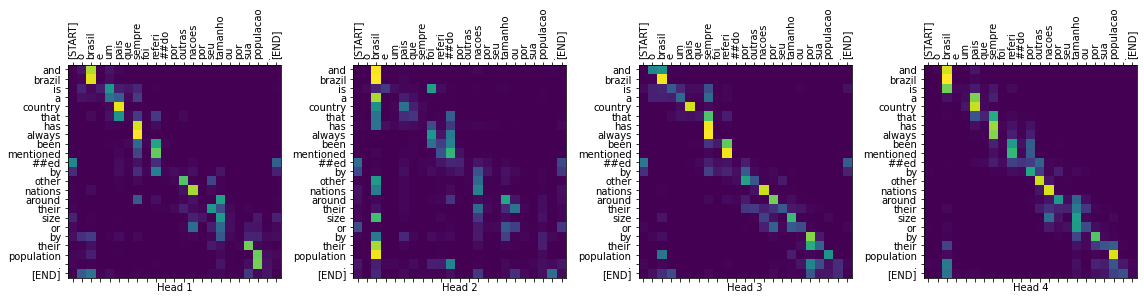

In [125]:
plot_attention_weights(paragraph, tokens, attn_weights[0])

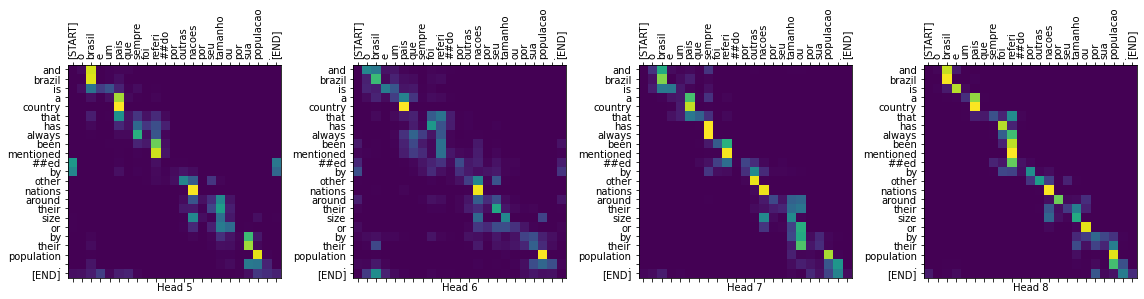

In [128]:
plot_attention_weights(paragraph, tokens, attn_weights[0])